In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp


In [17]:
file_path = "../1. data/raw/churn_prediction.csv"
df_churn_predictions = pd.read_csv(file_path)

Data Understanding 

In [18]:
# top 5 rows of the data
df_churn_predictions.head(5)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,52869,0,20.0,Mobile Phone,3,7.0,E wallet,Female,4.0,4,Fashion,5,Married,3,0,26.0,5.0,16.0,NaN,230
1,52942,0,13.0,Computer,1,9.0,Cash on Delivery,Female,4.0,4,Fashion,3,Single,2,0,26.0,11.0,NaN,9.0,234
2,52972,0,16.0,Mobile Phone,3,7.0,Debit Card,Male,3.0,4,Laptop & Accessory,3,Divorced,3,0,26.0,5.0,12.0,7.0,174
3,53125,0,5.0,Mobile Phone,1,16.0,Debit Card,Male,3.0,4,Fashion,4,Married,3,0,26.0,2.0,2.0,9.0,231
4,53367,0,9.0,Mobile Phone,1,28.0,Debit Card,Female,3.0,4,Laptop & Accessory,2,Divorced,3,1,26.0,1.0,2.0,8.0,165


In [19]:
# explore columns' name
df_churn_predictions.columns

Index(['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier',
       'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp',
       'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore',
       'MaritalStatus', 'NumberOfAddress', 'Complain',
       'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder', 'CashbackAmount'],
      dtype='object')

In [20]:
# number of records and features
print("Number of records:", df_churn_predictions.shape[0])
print("Number of features:", df_churn_predictions.shape[1])

Number of records: 5630
Number of features: 20


In [21]:
# Datatypes of each feature
print (df_churn_predictions.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [29]:
# Missing value overview
print(df_churn_predictions.isnull().sum())

CustomerID                       0
Churn                            0
Tenure                         264
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                 255
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
CashbackAmount                   0
dtype: int64


In [24]:
# Target distribution of churn users
print(df_churn_predictions['Churn'].value_counts())
print(df_churn_predictions['Churn'].value_counts(normalize=True) * 100)

Churn
0    4682
1     948
Name: count, dtype: int64
Churn
0    83.161634
1    16.838366
Name: proportion, dtype: float64


- Number of Records: There are 5,630 records in the dataset.

- Number of Features: There are 20 features in the dataset.

- Datatypes: The dataset contains 20 columns consisting of 7 float64, 8 int64, and 5 object types.

- Target Distribution: For the target variable Churn, class 0 has 4,682 instances (83.16%) and class 1 has 948 instances (16.84%).

Change data type 

In [ ]:
cat_cols = [
    'PreferredLoginDevice', 
    'PreferredPaymentMode', 
    'Gender', 
    'PreferedOrderCat', 
    'MaritalStatus'
]

for col in cat_cols:
    df_churn_predictions[col] = df_churn_predictions[col].astype('category')

df_churn_predictions['CustomerID'] = df_churn_predictions['CustomerID'].astype(str)

# Check the result
print(df_churn_predictions.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   CustomerID                   5630 non-null   object  
 1   Churn                        5630 non-null   int64   
 2   Tenure                       5366 non-null   float64 
 3   PreferredLoginDevice         5630 non-null   category
 4   CityTier                     5630 non-null   int64   
 5   WarehouseToHome              5379 non-null   float64 
 6   PreferredPaymentMode         5630 non-null   category
 7   Gender                       5630 non-null   category
 8   HourSpendOnApp               5375 non-null   float64 
 9   NumberOfDeviceRegistered     5630 non-null   int64   
 10  PreferedOrderCat             5630 non-null   category
 11  SatisfactionScore            5630 non-null   int64   
 12  MaritalStatus                5630 non-null   category
 13  Num

Missing values

In [30]:
df_churn_predictions.isnull().sum().sort_values(ascending = False)

DaySinceLastOrder              307
OrderAmountHikeFromlastYear    265
Tenure                         264
OrderCount                     258
CouponUsed                     256
HourSpendOnApp                 255
WarehouseToHome                251
CustomerID                       0
MaritalStatus                    0
Complain                         0
NumberOfAddress                  0
PreferedOrderCat                 0
SatisfactionScore                0
Churn                            0
NumberOfDeviceRegistered         0
Gender                           0
PreferredPaymentMode             0
CityTier                         0
PreferredLoginDevice             0
CashbackAmount                   0
dtype: int64

In [32]:
# Find missing values percentage in the data
round(df_churn_predictions.isnull().sum() / len(df_churn_predictions) * 100, 2).sort_values(ascending=False) 

DaySinceLastOrder              5.45
OrderAmountHikeFromlastYear    4.71
Tenure                         4.69
OrderCount                     4.58
CouponUsed                     4.55
HourSpendOnApp                 4.53
WarehouseToHome                4.46
CustomerID                     0.00
MaritalStatus                  0.00
Complain                       0.00
NumberOfAddress                0.00
PreferedOrderCat               0.00
SatisfactionScore              0.00
Churn                          0.00
NumberOfDeviceRegistered       0.00
Gender                         0.00
PreferredPaymentMode           0.00
CityTier                       0.00
PreferredLoginDevice           0.00
CashbackAmount                 0.00
dtype: float64

<Axes: >

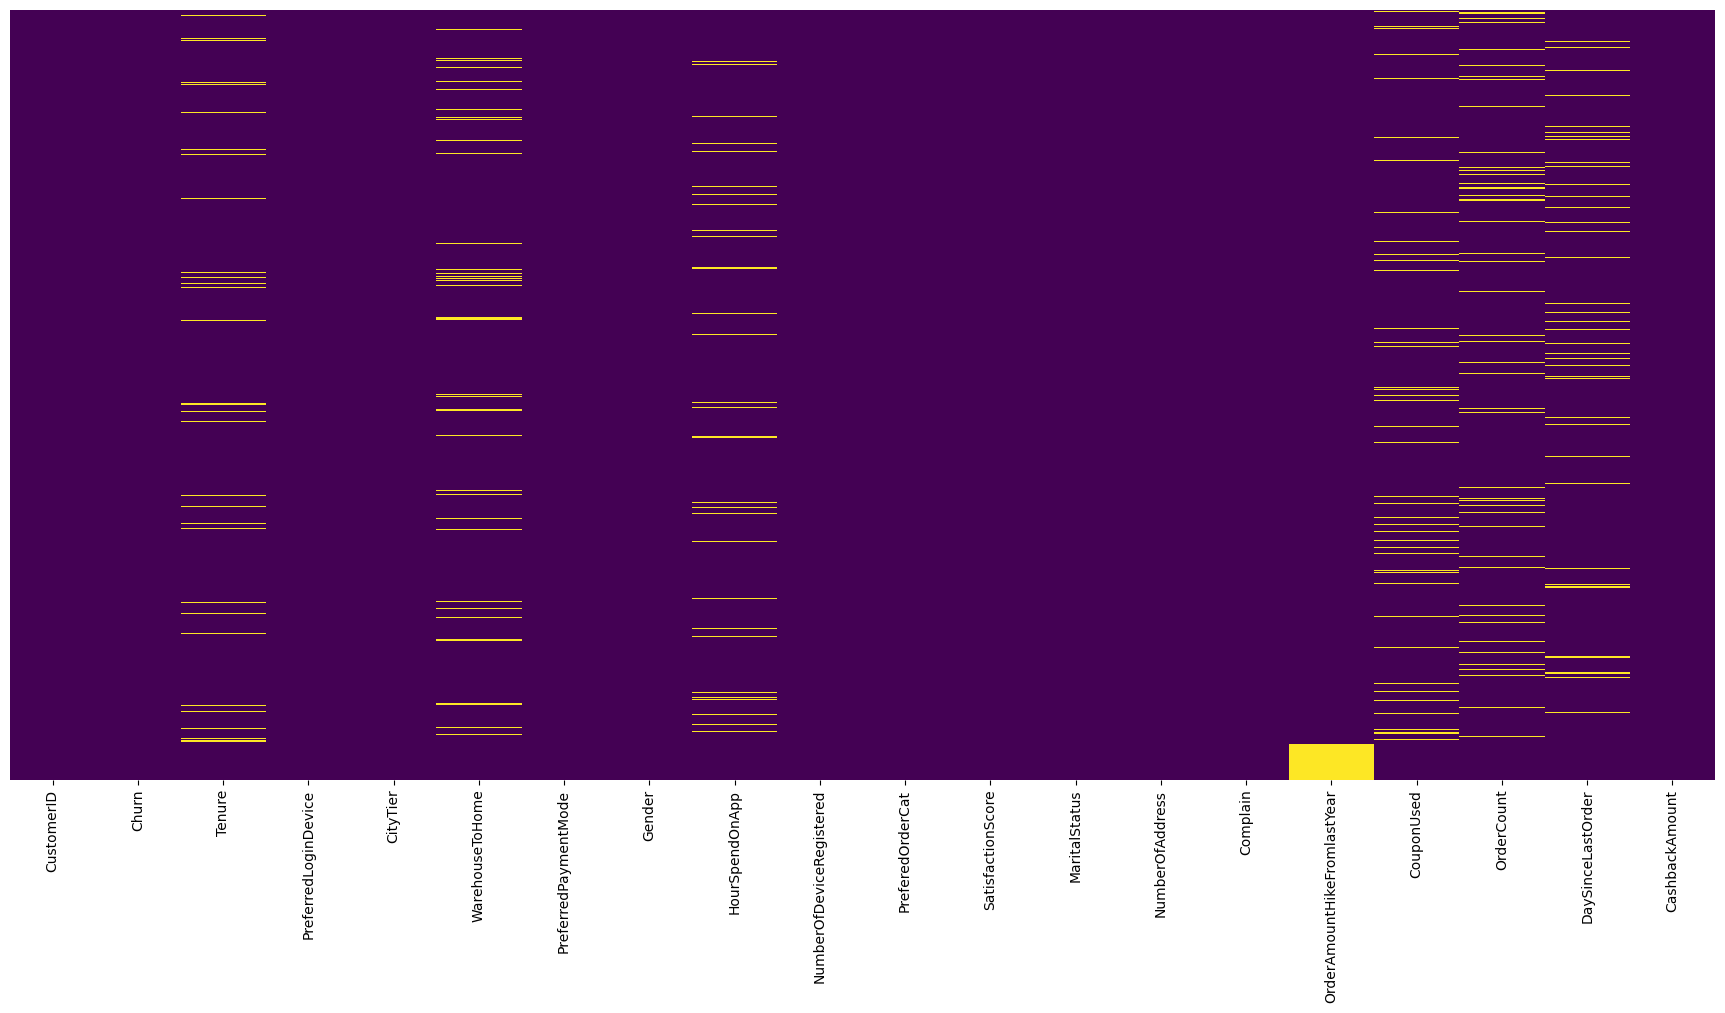

In [38]:
# plot the missing values
# make a figure size
plt.figure(figsize=(22, 10))
# plot the null values in each column
sns.heatmap(df_churn_predictions.isnull(), yticklabels=False, cbar=False, cmap='viridis')


<Axes: >

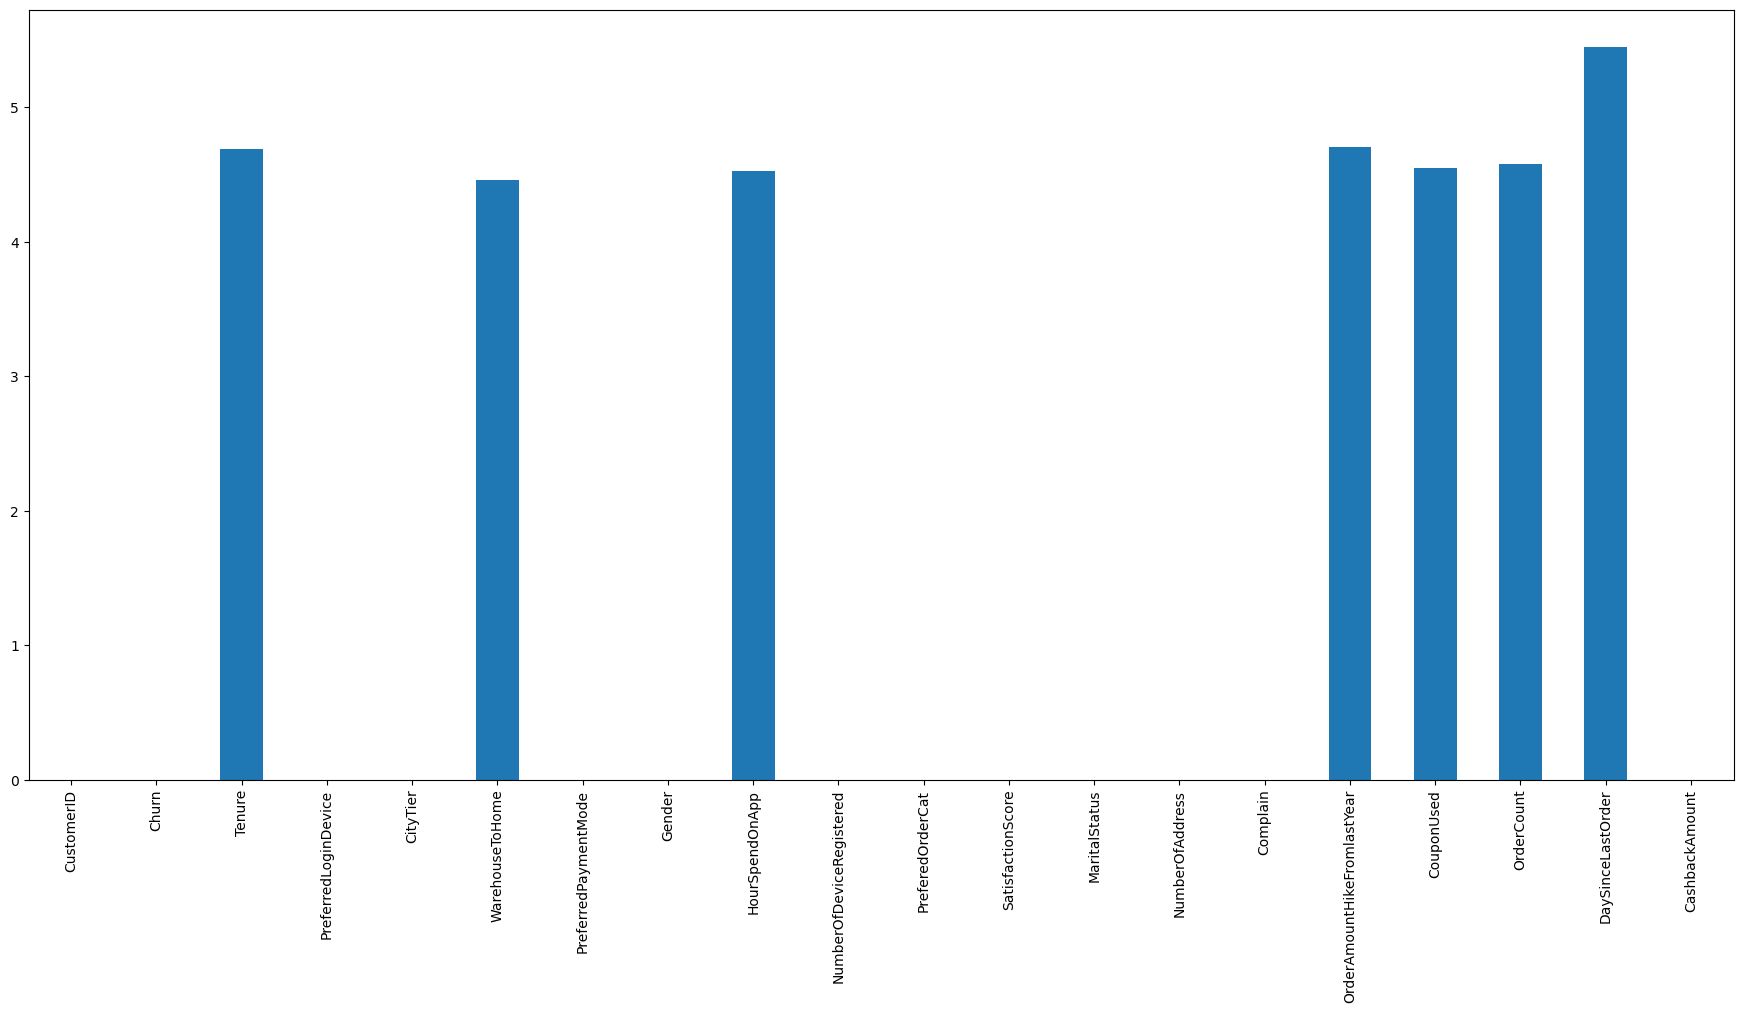

In [39]:
# plot the missing values by percentage

# make figure size
plt.figure(figsize=(22,10))

# plot the null values by their percentage in each column
missing_percentage = df_churn_predictions.isnull().sum()/len(df_churn_predictions)*100
missing_percentage.plot(kind='bar')



- Missing Value Overview: Missing values are present in several columns, specifically Tenure (264), WarehouseToHome (251), HourSpendOnApp (255), OrderAmountHikeFromlastYear (265), CouponUsed (256), OrderCount (258), and DaysSinceLastOrder (307).

- Duplicate: There are 0 completely duplicated rows in the dataset.

Deal with missing values

In [ ]:
# List of columns with missing values (based on your chart)
cols_to_fix = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp', 
    'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder'
]

# Loop to fill missing values using the median of each column
for col in cols_to_fix:
    median_value = df_churn_predictions[col].median()
    df_churn_predictions[col] = df_churn_predictions[col].fillna(median_value)

# Check the results
print(df_churn_predictions.isnull().sum())

CustomerID                     0
Churn                          0
Tenure                         0
PreferredLoginDevice           0
CityTier                       0
WarehouseToHome                0
PreferredPaymentMode           0
Gender                         0
HourSpendOnApp                 0
NumberOfDeviceRegistered       0
PreferedOrderCat               0
SatisfactionScore              0
MaritalStatus                  0
NumberOfAddress                0
Complain                       0
OrderAmountHikeFromlastYear    0
CouponUsed                     0
OrderCount                     0
DaySinceLastOrder              0
CashbackAmount                 0
dtype: int64


Find Duplications

In [23]:
# Duplicated value overview 
print(df_churn_predictions.duplicated().sum())

# Duplicated Customerid check
print(df_churn_predictions['CustomerID'].duplicated().sum())


0
0


Descriptive Statistics

In [26]:
df_churn_predictions.describe()

,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.221492
std,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.193869
min,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,146.000000
50%,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.000000
75%,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.000000
max,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,325.000000


Data Visualization 

Histogram

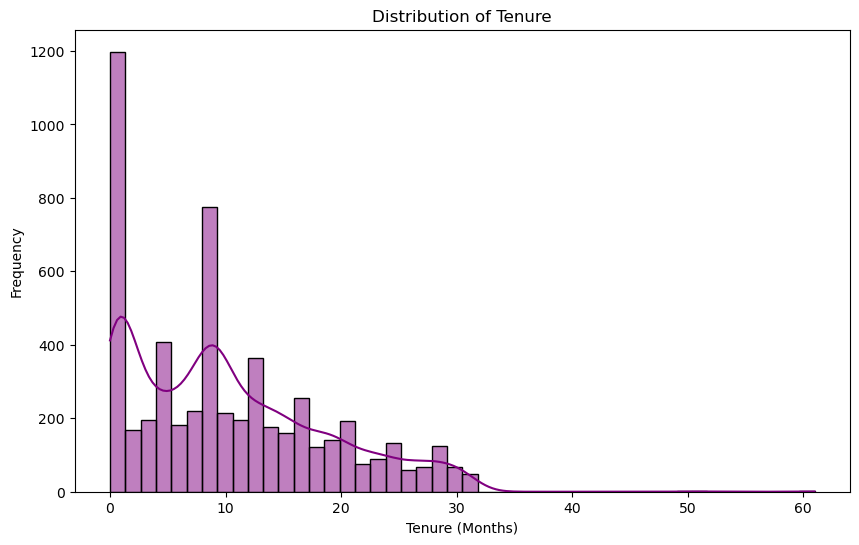

In [44]:
# Checking the distribution of 'Tenure' (or change to any other numeric column)
plt.figure(figsize=(10, 6))
sns.histplot(df_churn_predictions['Tenure'], kde=True, color='purple')
plt.title("Distribution of Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Frequency")
plt.show()

Scatter plot

<Axes: xlabel='Tenure', ylabel='CashbackAmount'>

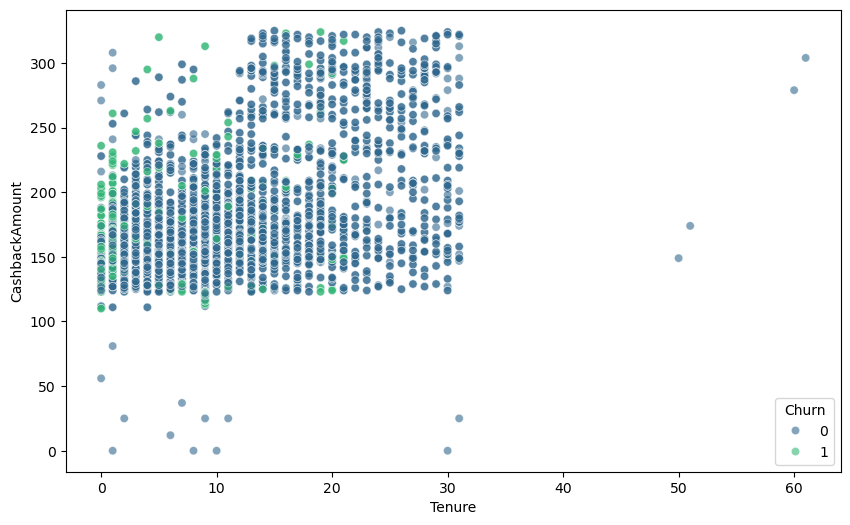

In [42]:
# Relationship between Tenure and CashbackAmount, colored by Churn
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_churn_predictions, 
    x='Tenure', 
    y='CashbackAmount', 
    hue='Churn', 
    palette='viridis',
    alpha=0.6
)

Heatmap

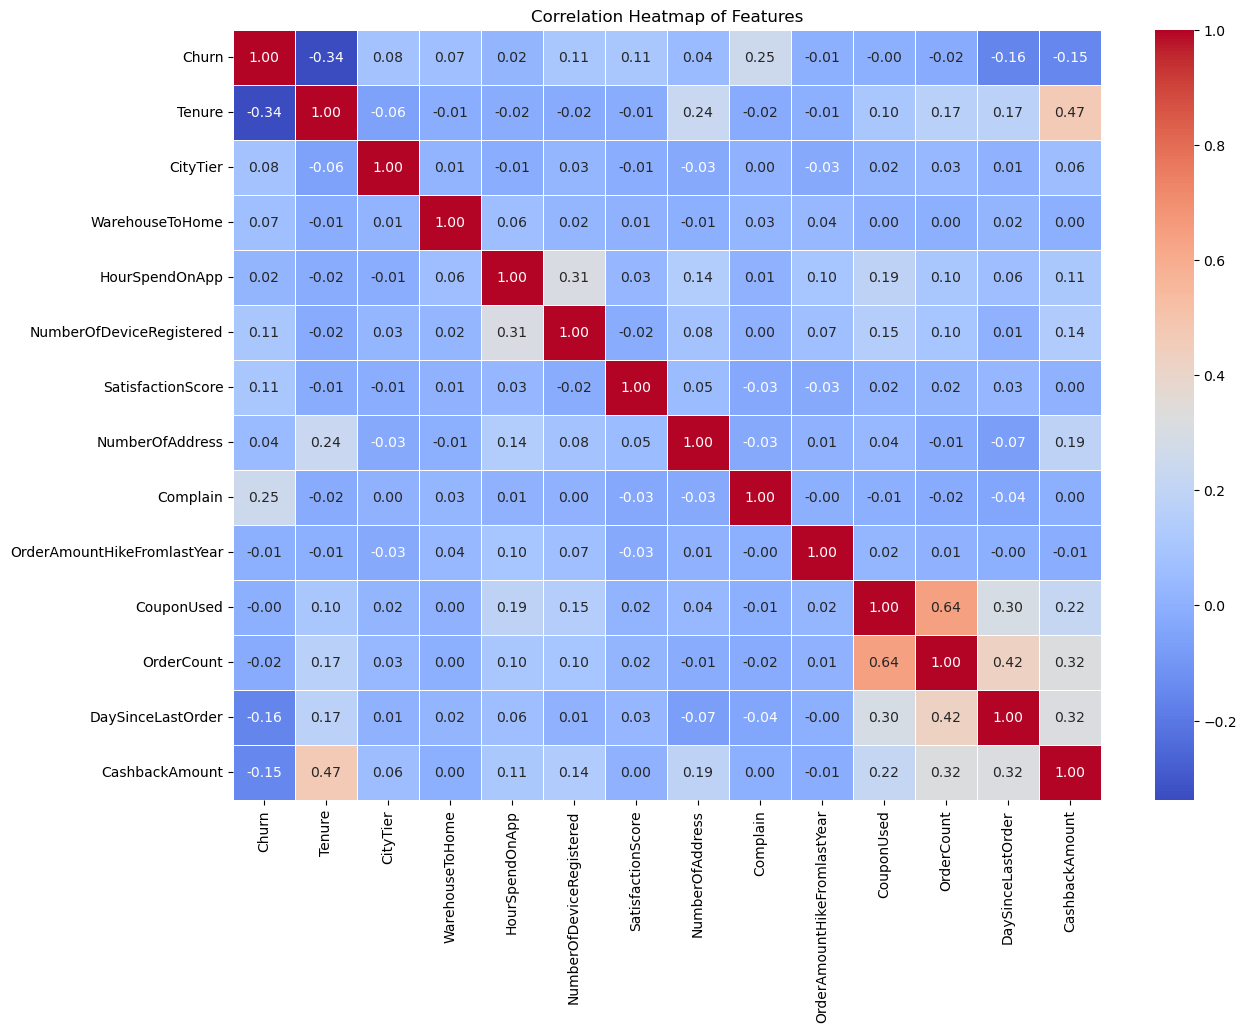

In [43]:
plt.figure(figsize=(14, 10))
correlation_matrix = df_churn_predictions.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

Bussiness insights and Recommendation

Business Insights
- High Churn Risk Among New Customers: The Distribution of Tenure histogram indicates that the highest frequency of customers is concentrated within the 0–1 month range. This confirms that the company faces a critical "early-stage" attrition problem, where a large portion of users leave shortly after joining.
- Correlation Between Complaints and Churn: The Correlation Heatmap reveals a positive correlation (0.25) between Complain and Churn. This demonstrates that customer dissatisfaction, manifested through complaints, is a significant driver for churn.
- Tenure and Reward Disparity: The Scatter Plot shows a clear pattern where the majority of churned users (indicated in green) are clustered in the low Tenure range, while also receiving lower CashbackAmount values compared to long-term users. This suggests that newer customers may not be receiving sufficient incentives to stay.

Recommendations
- Implement an Onboarding Retention Program: Given the high churn density at low Tenure, the business should prioritize an "Onboarding Retention Campaign" during the first three months. This could include personalized tutorials or special limited-time offers to stabilize user behavior early on.
- Proactive Complaint Management: Since Complain is positively correlated with Churn, the company must implement an automated alert system for complaints. Resolving these issues immediately is vital to preventing dissatisfied customers from leaving the platform.
- Dynamic Incentive Restructuring: The correlation between low Tenure and low CashbackAmount suggests a need to restructure reward policies. Providing early-stage users with higher cashback or introductory bonuses could bridge the engagement gap and improve the retention of new cohorts.